In [9]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.linear_model import Perceptron, LogisticRegression, SGDClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, PowerTransformer

# estudo árvores
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree

from sklearn.metrics import ConfusionMatrixDisplay

from xgboost import XGBClassifier
from xgboost import plot_importance

from lightgbm import LGBMClassifier
from lightgbm import plot_importance

from src.config import DADOS_LIMPOS
from src.graficos import plot_comparar_metricas_modelos
from src.models import RANDOM_STATE
from src.models import (
    grid_search_cv_classificador,
    treinar_e_validar_modelo_classificacao,
    organiza_resultados,
)

sns.set_theme(palette="bright")

In [2]:
df = pd.read_parquet(DADOS_LIMPOS)

df.head()

,area_mean,area_se,area_worst,compactness_mean,compactness_se,compactness_worst,concave points_mean,concave points_se,concave points_worst,concavity_mean,concavity_se,concavity_worst,diagnosis,fractal_dimension_mean,fractal_dimension_se,fractal_dimension_worst,perimeter_mean,perimeter_se,perimeter_worst,radius_mean,radius_se,radius_worst,smoothness_mean,smoothness_se,smoothness_worst,symmetry_mean,symmetry_se,symmetry_worst,texture_mean,texture_se,texture_worst
0,1001.0,153.40,2019.0,0.27760,0.04904,0.6656,0.14710,0.01587,0.2654,0.3001,0.05373,0.7119,M,0.07871,0.006193,0.11890,122.80,8.589,184.60,17.99,1.0950,25.38,0.11840,0.006399,0.1622,0.2419,0.03003,0.4601,10.38,0.9053,17.33
1,1326.0,74.08,1956.0,0.07864,0.01308,0.1866,0.07017,0.01340,0.1860,0.0869,0.01860,0.2416,M,0.05667,0.003532,0.08902,132.90,3.398,158.80,20.57,0.5435,24.99,0.08474,0.005225,0.1238,0.1812,0.01389,0.2750,17.77,0.7339,23.41
2,1203.0,94.03,1709.0,0.15990,0.04006,0.4245,0.12790,0.02058,0.2430,0.1974,0.03832,0.4504,M,0.05999,0.004571,0.08758,130.00,4.585,152.50,19.69,0.7456,23.57,0.10960,0.006150,0.1444,0.2069,0.02250,0.3613,21.25,0.7869,25.53
3,386.1,27.23,567.7,0.28390,0.07458,0.8663,0.10520,0.01867,0.2575,0.2414,0.05661,0.6869,M,0.09744,0.009208,0.17300,77.58,3.445,98.87,11.42,0.4956,14.91,0.14250,0.009110,0.2098,0.2597,0.05963,0.6638,20.38,1.1560,26.50
4,1297.0,94.44,1575.0,0.13280,0.02461,0.2050,0.10430,0.01885,0.1625,0.1980,0.05688,0.4000,M,0.05883,0.005115,0.07678,135.10,5.438,152.20,20.29,0.7572,22.54,0.10030,0.011490,0.1374,0.1809,0.01756,0.2364,14.34,0.7813,16.67


In [3]:
X = df.drop(columns=["diagnosis"])
y = df["diagnosis"]

In [4]:
le = LabelEncoder()

y = le.fit_transform(y)

y[:20]

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0])

In [5]:
seletor_mi = SelectKBest(mutual_info_classif, k=15)

X_mi = seletor_mi.fit_transform(X, y)

X_mi.shape

(569, 15)

In [6]:
seletor_mi.get_feature_names_out()

array(['area_mean', 'area_se', 'area_worst', 'compactness_mean',
       'compactness_worst', 'concave points_mean', 'concave points_worst',
       'concavity_mean', 'concavity_worst', 'perimeter_mean',
       'perimeter_se', 'perimeter_worst', 'radius_mean', 'radius_se',
       'radius_worst'], dtype=object)

In [7]:
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

In [8]:
preprocessamento = Pipeline(
    steps=[
        ("scaler", PowerTransformer()),
        ("selector", SelectKBest(mutual_info_classif, k=15))
    ]
)

preprocessamento_arvore = Pipeline(
    steps=[
        ("selector", SelectKBest(mutual_info_classif, k=15))
    ]
)

In [10]:
classificadores = {
    "DummyClassifier": {
        "preprocessor": None,
        "classificador": DummyClassifier(strategy="stratified")
    },
    "Perceptron": {
        "preprocessor": preprocessamento,
        "classificador": Perceptron()
    },
    "LogisticRegression": {
        "preprocessor": preprocessamento,
        "classificador": LogisticRegression()
    },
    "SGDClassifier": {
        "preprocessor": preprocessamento,
        "classificador": SGDClassifier()
    },
    
    # adicionar modelos baseados em árvores de decisão
    
    "DecisionTreeClassifier": {
        "preprocessor": preprocessamento_arvore,
        "classificador": DecisionTreeClassifier()
    },
    "RandomForestClassifier": {
        "preprocessor": preprocessamento_arvore,
        "classificador": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)
    },
    "XGBClassifier": {
        "preprocessor": preprocessamento_arvore,
        "classificador": XGBClassifier(random_state=RANDOM_STATE, n_jobs=-1)
    },
    "LGBMClassifier": {
        "preprocessor": preprocessamento_arvore,
        "classificador": LGBMClassifier(random_state=RANDOM_STATE, n_jobs=-1, verbose=-1)
    },
}

In [14]:
resultados = {
    nome_modelo: treinar_e_validar_modelo_classificacao(X, y, kf, **classificador)
    for nome_modelo, classificador in classificadores.items()
}

df_resultados = organiza_resultados(resultados)

df_resultados

,model,fit_time,score_time,test_accuracy,test_balanced_accuracy,test_f1,test_precision,test_recall,test_roc_auc,test_average_precision,time_seconds
0,DummyClassifier,0.001087,0.013192,0.447368,0.409597,0.258824,0.261905,0.255814,0.500491,0.377424,0.014279
1,DummyClassifier,0.000991,0.010168,0.587719,0.563544,0.45977,0.454545,0.465116,0.535375,0.395553,0.011158
2,DummyClassifier,0.000674,0.004659,0.614035,0.565476,0.421053,0.470588,0.380952,0.373016,0.336341,0.005333
3,DummyClassifier,0.000642,0.005497,0.508772,0.487103,0.377778,0.354167,0.404762,0.474206,0.357561,0.006139
4,DummyClassifier,0.001293,0.008708,0.584071,0.576626,0.494624,0.45098,0.547619,0.523642,0.383726,0.01
5,Perceptron,0.0901,0.006271,0.938596,0.918605,0.911392,1.0,0.837209,0.987881,0.982831,0.096371
6,Perceptron,0.059265,0.006218,0.894737,0.865051,0.842105,0.969697,0.744186,0.985915,0.977328,0.065483
7,Perceptron,0.05907,0.005631,0.921053,0.922619,0.896552,0.866667,0.928571,0.982143,0.978283,0.064701
8,Perceptron,0.057792,0.007608,0.95614,0.960317,0.942529,0.911111,0.97619,0.995701,0.993515,0.0654
9,Perceptron,0.061682,0.00672,0.964602,0.952381,0.95,1.0,0.904762,0.996982,0.995172,0.068403


In [15]:
df_resultados.groupby("model").mean().sort_values("test_recall")

,fit_time,score_time,test_accuracy,test_balanced_accuracy,test_f1,test_precision,test_recall,test_roc_auc,test_average_precision,time_seconds
model,,,,,,,,,,
DummyClassifier,0.000937,0.008445,0.548393,0.520469,0.40241,0.398437,0.410853,0.481346,0.370121,0.009382
DecisionTreeClassifier,0.045284,0.006044,0.912172,0.905172,0.880699,0.892061,0.877519,0.905172,0.82561,0.051328
Perceptron,0.065582,0.00649,0.935026,0.923795,0.908516,0.949495,0.878184,0.989724,0.985426,0.072072
RandomForestClassifier,0.209026,0.058211,0.942028,0.934762,0.919985,0.939632,0.905869,0.98843,0.983118,0.267237
LGBMClassifier,0.33541,0.012279,0.943782,0.936827,0.923299,0.938601,0.910078,0.986523,0.980717,0.347689
XGBClassifier,0.183975,0.010734,0.938519,0.932751,0.916798,0.924712,0.910299,0.985474,0.980406,0.194709
LogisticRegression,0.072176,0.008009,0.952585,0.947818,0.935613,0.944606,0.929125,0.992078,0.989293,0.080185
SGDClassifier,0.068044,0.007615,0.943798,0.942926,0.925117,0.915069,0.938981,0.988147,0.985857,0.075659


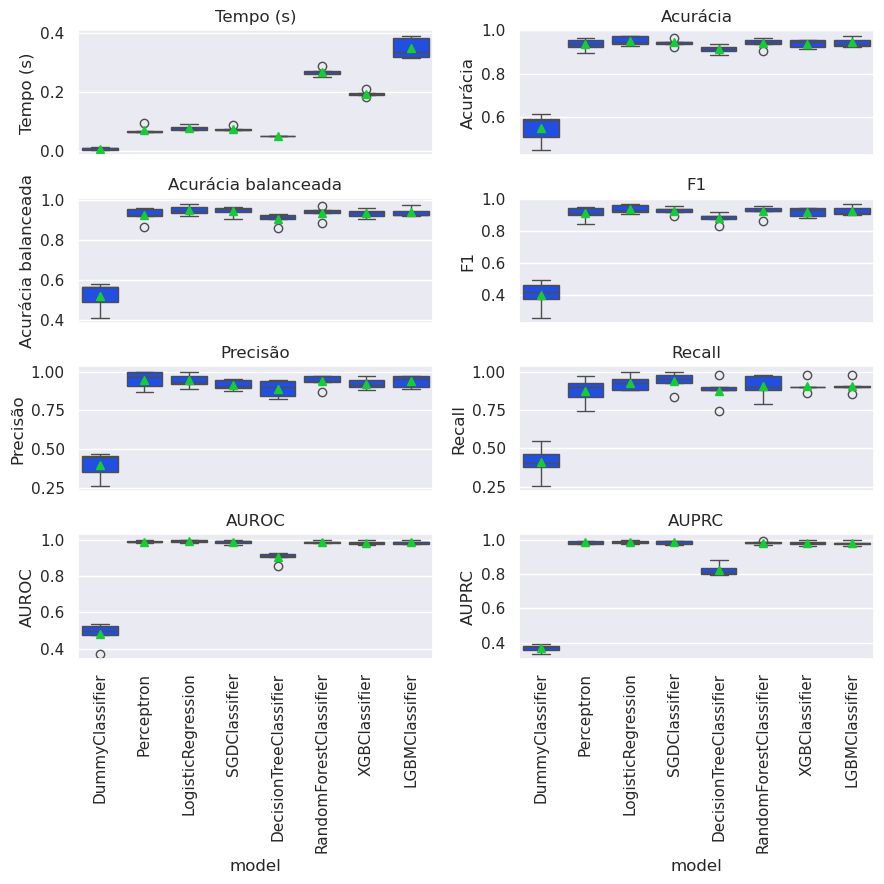

In [16]:
plot_comparar_metricas_modelos(df_resultados)

Principais hiperparâmetros do **LGBMClassifier**:


- **`max_depth`**: Profundidade máxima da árvore.
- **`num_leaves`**: Número máximo de folhas por árvore.
- **`min_child_samples`**: Mínimo de amostras necessárias em um nó folha.
- **`min_split_gain`**: Redução mínima de perda para realizar uma divisão.
- **`subsample`**: Proporção de amostras usadas para construir cada árvore.
- **`colsample_bytree`**: Proporção de features para construir cada árvore.
- **`n_estimators`**: Número de árvores.
- **`learning_rate`**: Taxa de aprendizado.
- **`reg_alpha`**: Regularização L1 para pesos.
- **`reg_lambda`**: Regularização L2 para pesos.
- **`scale_pos_weight`**: Controla o balanceamento de classes quando há classes desbalanceadas.


In [17]:
np.bincount(y)

array([357, 212])

In [18]:
scale_pos_weight = np.bincount(y)[0] / np.bincount(y)[1]
scale_pos_weight

1.6839622641509433

In [19]:
# param grid para o modelo em estudo
param_grid = {
    "clf__max_depth": [3, 6],  # Profundidade máxima da árvore (<=0 significa sem limite)
    # "clf__num_leaves": [10, 20, 31, 50],  # Número máximo de folhas por árvore
    # "clf__min_child_samples": [10, 20, 50],  # Mínimo de amostras em um nó folha
    # "clf__min_split_gain": [0.0, 0.1, 0.3],  # Redução mínima de perda para divisão
    "clf__subsample": [0.6, 0.8, 1.0],  # Proporção de amostras usadas para cada árvore
    "clf__colsample_bytree": [0.6, 0.8, 1.0],  # Proporção de features para construção de cada árvore
    "clf__learning_rate": [0.05, 0.1, 0.3],  # Taxa de aprendizado
    "clf__n_estimators": [10, 50, 100],  # Número de árvores
    "clf__reg_alpha": [0.0, 0.1, 1.0],  # Regularização L1
    "clf__reg_lambda": [0.0, 0.1, 1.0],  # Regularização L2
    "clf__scale_pos_weight": [1, scale_pos_weight],  # Peso das classes
}

In [20]:
# classificador baseado em árvore de decisão
clf = LGBMClassifier(random_state=RANDOM_STATE, n_jobs=-1, verbose=-1)

grid_search = grid_search_cv_classificador(
    clf, param_grid, kf, preprocessamento_arvore, refit_metric="recall"
)

grid_search

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('preprocessor',
                                        Pipeline(steps=[('selector',
                                                         SelectKBest(k=15,
                                                                     score_func=<function mutual_info_classif at 0x75b25e5adee0>))])),
                                       ('clf',
                                        LGBMClassifier(n_jobs=-1,
                                                       random_state=42,
                                                       verbose=-1))]),
             n_jobs=-1,
             param_grid={'clf__colsample_bytree': [0.6, 0.8, 1.0],
                         'clf__learning_rate': [0.05, 0.1, 0.3],
                         'clf__max_depth': [3, 6],
                         'clf__n_estimators': [10, 50, 100],
                         'clf__reg_alpha': [0.0, 0.1, 1.0],
                         'clf__reg_lambda': [0.0, 0.1, 1.0],
                         'clf__scale_pos_weight': [1, 1.6839622641509433],
                         'clf__subsample': [0.6, 0.8, 1.0]},
             refit='recall',
             scoring=['accuracy', 'balanced_accuracy', 'f1', 'precision',
                      'recall', 'roc_auc', 'average_precision'],
             verbose=1)

In [21]:
grid_search.fit(X, y)

Fitting 5 folds for each of 2916 candidates, totalling 14580 fits


GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('preprocessor',
                                        Pipeline(steps=[('selector',
                                                         SelectKBest(k=15,
                                                                     score_func=<function mutual_info_classif at 0x75b25e5adee0>))])),
                                       ('clf',
                                        LGBMClassifier(n_jobs=-1,
                                                       random_state=42,
                                                       verbose=-1))]),
             n_jobs=-1,
             param_grid={'clf__colsample_bytree': [0.6, 0.8, 1.0],
                         'clf__learning_rate': [0.05, 0.1, 0.3],
                         'clf__max_depth': [3, 6],
                         'clf__n_estimators': [10, 50, 100],
                         'clf__reg_alpha': [0.0, 0.1, 1.0],
                         'clf__reg_lambda': [0.0, 0.1, 1.0],
                         'clf__scale_pos_weight': [1, 1.6839622641509433],
                         'clf__subsample': [0.6, 0.8, 1.0]},
             refit='recall',
             scoring=['accuracy', 'balanced_accuracy', 'f1', 'precision',
                      'recall', 'roc_auc', 'average_precision'],
             verbose=1)

In [22]:
grid_search.best_params_

{'clf__colsample_bytree': 0.6,
 'clf__learning_rate': 0.05,
 'clf__max_depth': 3,
 'clf__n_estimators': 50,
 'clf__reg_alpha': 0.0,
 'clf__reg_lambda': 0.1,
 'clf__scale_pos_weight': 1.6839622641509433,
 'clf__subsample': 0.6}

In [23]:
grid_search.best_score_

0.948062015503876

In [24]:
grid_search.best_estimator_

Pipeline(steps=[('preprocessor',
                 Pipeline(steps=[('selector',
                                  SelectKBest(k=15,
                                              score_func=<function mutual_info_classif at 0x75b25e5adee0>))])),
                ('clf',
                 LGBMClassifier(colsample_bytree=0.6, learning_rate=0.05,
                                max_depth=3, n_estimators=50, n_jobs=-1,
                                random_state=42, reg_lambda=0.1,
                                scale_pos_weight=1.6839622641509433,
                                subsample=0.6, verbose=-1))])

In [25]:
grid_search.best_estimator_["preprocessor"].get_feature_names_out()

array(['area_mean', 'area_se', 'area_worst', 'compactness_mean',
       'compactness_worst', 'concave points_mean', 'concave points_worst',
       'concavity_mean', 'concavity_worst', 'perimeter_mean',
       'perimeter_se', 'perimeter_worst', 'radius_mean', 'radius_se',
       'radius_worst'], dtype=object)

In [28]:
grid_search.best_estimator_["clf"].booster_.feature_importance()

array([13, 28, 33,  9,  7, 22, 36,  8, 23,  1,  9, 46,  6,  9, 16],
      dtype=int32)

In [29]:
grid_search.best_estimator_["clf"].booster_.feature_importance().argsort()

array([ 9, 12,  4,  7,  3, 10, 13,  0, 14,  5,  8,  1,  2,  6, 11])

In [30]:
indices_weight = grid_search.best_estimator_["clf"].booster_.feature_importance().argsort()

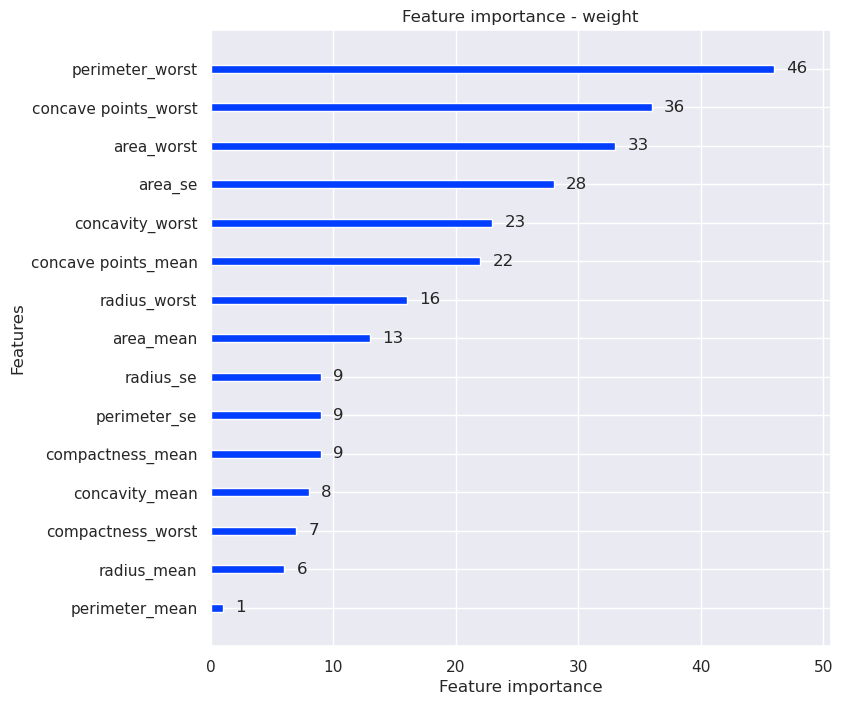

In [31]:
fig, ax = plt.subplots(figsize=(8, 8))

plot_importance(
    grid_search.best_estimator_["clf"],
    ax=ax,
    title="Feature importance - weight",
)

plt.yticks(
    np.arange(len(grid_search.best_estimator_["preprocessor"].get_feature_names_out())),
    grid_search.best_estimator_["preprocessor"].get_feature_names_out()[indices_weight]
)

plt.show()

In [40]:
perm_imp = permutation_importance(
    grid_search.best_estimator_,
    X,
    y,
    n_repeats=10,
    random_state=RANDOM_STATE
)

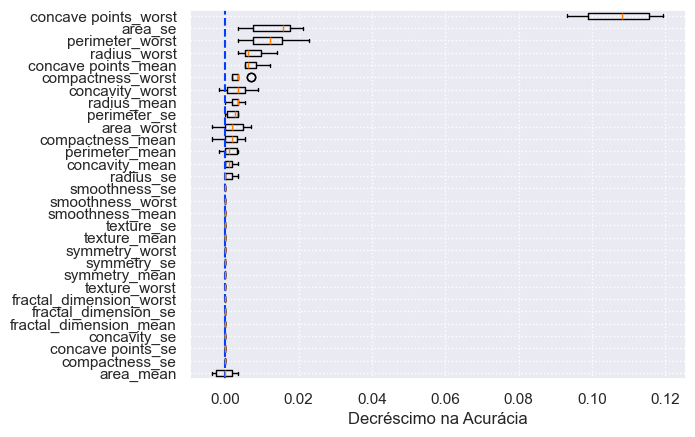

In [41]:
fig, ax = plt.subplots()

ordem = perm_imp.importances_mean.argsort()

ax.boxplot(perm_imp.importances[ordem].T, vert=False, tick_labels=X.columns[ordem])
ax.axvline(x=0, linestyle="--")
ax.set_xlabel("Decréscimo na Acurácia")
ax.grid(True, linestyle=":")

plt.show()

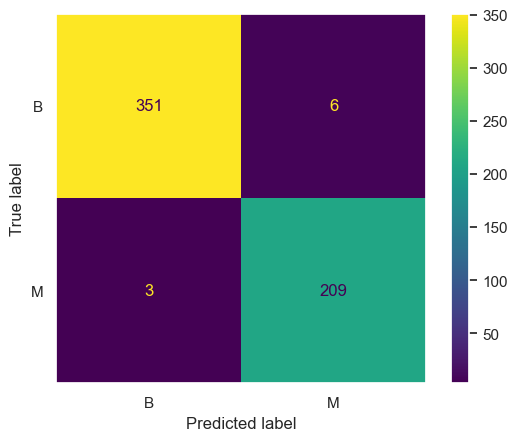

In [42]:
ConfusionMatrixDisplay.from_estimator(
    grid_search.best_estimator_,
    X,
    y,
    display_labels=le.classes_,
)
plt.grid(False)
plt.show()

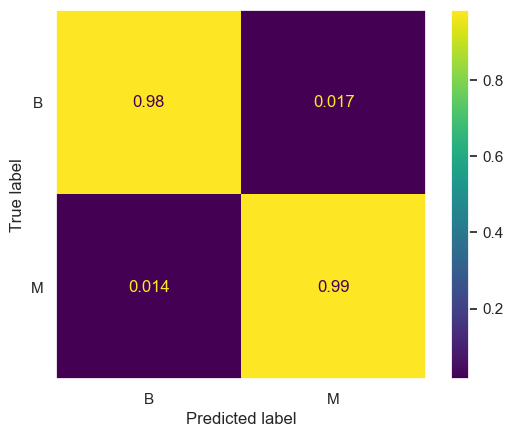

In [43]:
ConfusionMatrixDisplay.from_estimator(
    grid_search.best_estimator_,
    X,
    y,
    display_labels=le.classes_,
    normalize="true",
)
plt.grid(False)
plt.show()